In [3]:

from pathlib import Path
from PIL import Image, ImageOps
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import hashlib
import os

DATASET_ROOT = Path(
    r"C:\Users\SWARA\Documents\Handwriting Analysis\dataset"
)

# Change this if your original images are directly inside dataset/
RAW_DIR = DATASET_ROOT

METADATA_DIR = DATASET_ROOT / "metadata"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

METADATA_CSV = METADATA_DIR / "dataset_metadata.csv"

SUPPORTED_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff",
    ".webp", ".gif"
}

print("Dataset root:", DATASET_ROOT)
print("Raw directory:", RAW_DIR)
print("Raw directory exists:", RAW_DIR.exists())

Dataset root: C:\Users\SWARA\Documents\Handwriting Analysis\dataset
Raw directory: C:\Users\SWARA\Documents\Handwriting Analysis\dataset
Raw directory exists: True


In [4]:

if not RAW_DIR.exists():
    raise FileNotFoundError(
        f"Raw directory not found: {RAW_DIR}\n"
        "Update RAW_DIR to your actual original-image folder."
    )

image_files = sorted(
    p for p in RAW_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
)

print("Total supported image files:", len(image_files))
print("Extension distribution:")

extension_counts = pd.Series(
    [p.suffix.lower() for p in image_files],
    name="extension"
).value_counts().rename_axis("extension").reset_index(name="count")

display(extension_counts)

if not image_files:
    raise ValueError("No supported images found.")

Total supported image files: 780
Extension distribution:


,extension,count
0,.jpg,641
1,.jpeg,138
2,.png,1


In [5]:

metadata_records = []

for path in tqdm(image_files, desc="Creating metadata"):
    record = {
        "filename": path.name,
        "relative_path": str(path.relative_to(RAW_DIR)),
        "absolute_path": str(path.resolve()),
        "extension": path.suffix.lower(),
        "file_size_bytes": path.stat().st_size,
        "width": None,
        "height": None,
        "aspect_ratio": None,
        "format": None,
        "mode": None,
        "is_valid": False,
        "error": None
    }

    try:
        with Image.open(path) as im:
            im.seek(0)
            im.load()

            width, height = im.size

            record.update({
                "width": width,
                "height": height,
                "aspect_ratio": width / height if height else None,
                "format": im.format,
                "mode": im.mode,
                "is_valid": width > 0 and height > 0
            })

    except Exception as e:
        record["error"] = str(e)

    metadata_records.append(record)

metadata_df = pd.DataFrame(metadata_records)
metadata_df.to_csv(METADATA_CSV, index=False)

print("Metadata saved:", METADATA_CSV)
display(metadata_df.head())
display(metadata_df["is_valid"].value_counts(dropna=False))

Creating metadata:   0%|          | 0/780 [00:00<?, ?it/s]

Metadata saved: C:\Users\SWARA\Documents\Handwriting Analysis\dataset\metadata\dataset_metadata.csv


,filename,relative_path,absolute_path,extension,file_size_bytes,width,height,aspect_ratio,format,mode,is_valid,error
0,page001.jpg,page001.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,.jpg,877355,1898,2628,0.722222,JPEG,RGB,True,None
1,page002.jpg,page002.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,.jpg,916259,2013,2579,0.780535,JPEG,RGB,True,None
2,page003.jpg,page003.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,.jpg,769733,1721,2408,0.714701,JPEG,RGB,True,None
3,page004.jpg,page004.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,.jpg,675979,1852,2468,0.750405,JPEG,RGB,True,None
4,page005.jpg,page005.jpg,C:\Users\SWARA\Documents\Handwriting Analysis\...,.jpg,754599,1817,2341,0.776164,JPEG,RGB,True,None


is_valid
True    780
Name: count, dtype: int64

In [6]:

print("Total files:", len(metadata_df))
print("Valid images:", metadata_df["is_valid"].sum())
print("Invalid images:", (~metadata_df["is_valid"]).sum())
print("Total size (MB):", round(metadata_df["file_size_bytes"].sum() / 1e6, 2))

print("\nDimensions:")
display(
    metadata_df.loc[metadata_df["is_valid"], ["width", "height"]].describe()
)

print("\nImage modes:")
display(metadata_df["mode"].value_counts(dropna=False))

print("\nExtension distribution:")
display(metadata_df["extension"].value_counts())

invalid_df = metadata_df[~metadata_df["is_valid"]]
if not invalid_df.empty:
    display(invalid_df[["relative_path", "error"]])

metadata_df.to_excel(
    METADATA_DIR / "dataset_metadata.xlsx",
    index=False
)

Total files: 780
Valid images: 780
Invalid images: 0
Total size (MB): 447.49

Dimensions:


,width,height
count,780.000000,780.000000
mean,1172.464103,1530.220513
std,1146.834592,1561.066306
min,224.000000,224.000000
25%,224.000000,224.000000
50%,867.000000,1174.500000
75%,2099.000000,2939.500000
max,6836.000000,10002.000000



Image modes:


mode
RGB     779
RGBA      1
Name: count, dtype: int64


Extension distribution:


extension
.jpg     641
.jpeg    138
.png       1
Name: count, dtype: int64

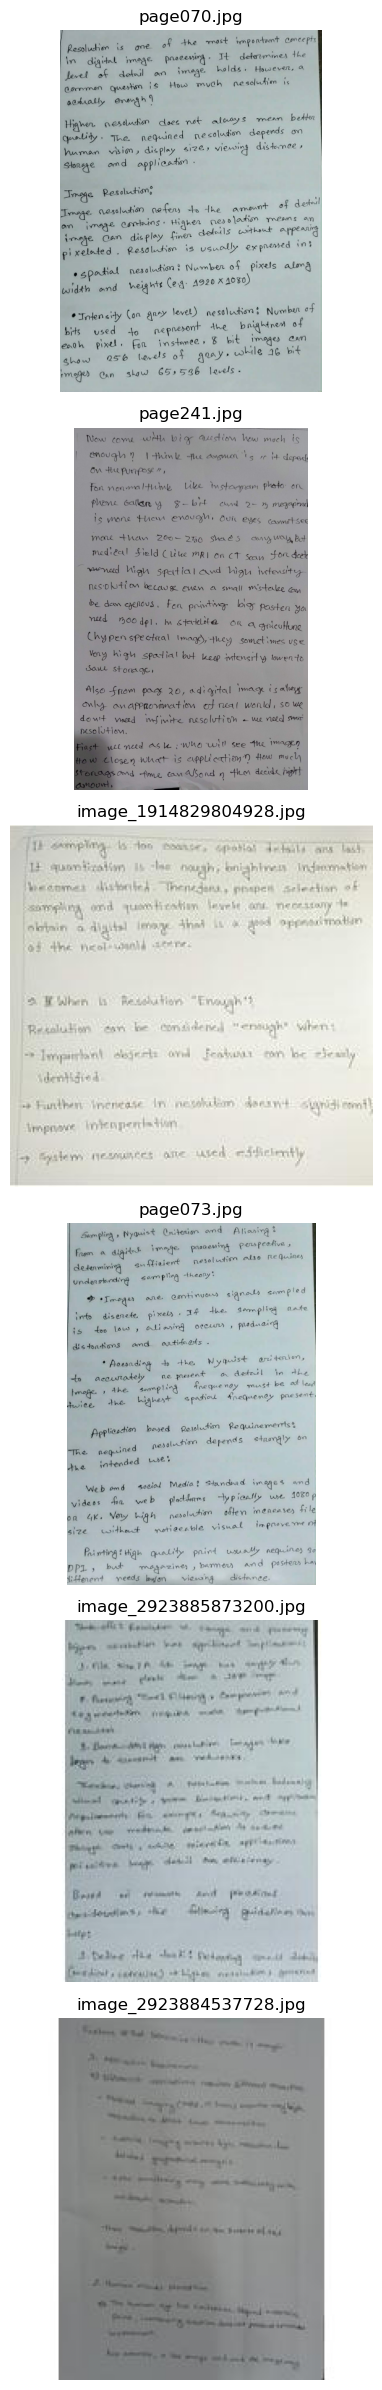

In [7]:

import matplotlib.pyplot as plt
import random

valid_paths = metadata_df.loc[
    metadata_df["is_valid"], "absolute_path"
].tolist()

sample_paths = random.sample(
    valid_paths, min(6, len(valid_paths))
)

fig, axes = plt.subplots(
    len(sample_paths), 1,
    figsize=(10, 4 * len(sample_paths))
)

axes = np.atleast_1d(axes)

for ax, path in zip(axes, sample_paths):
    with Image.open(path) as im:
        ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
    ax.set_title(Path(path).name)
    ax.axis("off")

plt.tight_layout()
plt.show()